# Export raw or Suite2p-registered two-channel recordings as videos

Set `VIDEO_SOURCE` to export either the raw interleaved TIFF or Suite2p's registered binaries. In either mode the notebook writes grayscale red/structural, green/functional, and optional side-by-side MP4 videos.

Frames are streamed rather than loading the complete recording into RAM. Contrast limits are estimated from evenly distributed sample frames and remain fixed throughout each video. Playback defaults to the 7.52 Hz acquisition rate.


In [16]:
from pathlib import Path
from contextlib import nullcontext
import json
import subprocess

import numpy as np
import tifffile

try:
    import imageio_ffmpeg
except ImportError as exc:
    raise ImportError(
        'This notebook requires imageio-ffmpeg. Run: %pip install imageio-ffmpeg'
    ) from exc

# ---- Choose the source ----
VIDEO_SOURCE = 'raw_tiff'  # 'raw_tiff' or 'suite2p_registered'

# Raw TIFF settings
INPUT_DIR = Path(
    '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/'
    'sub-03_id-MY_71_R/ses-217_date-20260731/funcimg/run-02/'
)
INPUT_FILENAME = '71rtask_00009_dynamic_bidiphase_destriped_undistorted.tif'
INPUT_TIFF = INPUT_DIR / INPUT_FILENAME

# Shared derivatives/run location and Suite2p location
OUTPUT_BASE_DIR = Path(
    '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/'
    'sub-03_id-MY_71_R/ses-217_date-20260731/funcimg'
)
RUN_NAME = 'run-02'
RUN_DIR = OUTPUT_BASE_DIR / RUN_NAME
SUITE2P_PLANE_DIR = RUN_DIR / 'suite2p' / 'plane0'
OUTPUT_DIR = RUN_DIR / 'videos'

FPS = 7.52
N_CHANNELS = 2
STRUCTURAL_CHANNEL_ZERO_BASED = 0  # raw TIFF acquisition channel 1, red
FUNCTIONAL_CHANNEL_ZERO_BASED = 1  # raw TIFF acquisition channel 2, green

WRITE_RED_VIDEO = True
WRITE_GREEN_VIDEO = True
WRITE_SIDE_BY_SIDE_VIDEO = True
OVERWRITE = True

# Fixed display scaling, calculated from sampled source frames.
CONTRAST_SAMPLE_FRAMES = 500
BLACK_PERCENTILE = 1.0
WHITE_PERCENTILE = 99.8
GAMMA = 1.0

# H.264 encoding. Lower CRF gives higher quality and larger files.
VIDEO_CRF = 18
VIDEO_PRESET = 'medium'
MAX_TIMEPOINTS = None  # set to 500 for a short test; None exports everything

if VIDEO_SOURCE not in {'raw_tiff', 'suite2p_registered'}:
    raise ValueError("VIDEO_SOURCE must be 'raw_tiff' or 'suite2p_registered'")
if WHITE_PERCENTILE <= BLACK_PERCENTILE:
    raise ValueError('WHITE_PERCENTILE must exceed BLACK_PERCENTILE')

if VIDEO_SOURCE == 'raw_tiff':
    if not INPUT_TIFF.is_file():
        raise FileNotFoundError(f'Input TIFF not found: {INPUT_TIFF}')
    VIDEO_STEM = f'{INPUT_TIFF.stem}_raw'
    SOURCE_DESCRIPTION = str(INPUT_TIFF)
else:
    ops_path = SUITE2P_PLANE_DIR / 'ops.npy'
    if not ops_path.is_file():
        raise FileNotFoundError(f'Suite2p ops.npy not found: {ops_path}')
    suite2p_ops = np.load(ops_path, allow_pickle=True).item()

    def resolve_suite2p_binary(ops_key, fallback_name):
        candidates = []
        saved = suite2p_ops.get(ops_key)
        if saved:
            candidates.append(Path(saved))
        candidates.append(SUITE2P_PLANE_DIR / fallback_name)
        for candidate in candidates:
            if candidate.is_file():
                return candidate
        raise FileNotFoundError(
            f'Could not find {fallback_name}; checked: ' +
            ', '.join(map(str, candidates)))

    GREEN_BINARY = resolve_suite2p_binary('reg_file', 'data.bin')
    RED_BINARY = resolve_suite2p_binary('reg_file_chan2', 'data_chan2.bin')
    VIDEO_STEM = 'suite2p_registered'
    SOURCE_DESCRIPTION = str(SUITE2P_PLANE_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RED_VIDEO = OUTPUT_DIR / f'{VIDEO_STEM}_red_structural.mp4'
GREEN_VIDEO = OUTPUT_DIR / f'{VIDEO_STEM}_green_functional.mp4'
SIDE_BY_SIDE_VIDEO = OUTPUT_DIR / f'{VIDEO_STEM}_red_green_side_by_side.mp4'

print('Video source:', VIDEO_SOURCE)
print('Source:', SOURCE_DESCRIPTION)
print('Output directory:', OUTPUT_DIR)
print('Frame rate:', FPS, 'Hz')


Video source: raw_tiff
Source: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-217_date-20260731/funcimg/run-02/71rtask_00009_dynamic_bidiphase_destriped_undistorted.tif
Output directory: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-217_date-20260731/funcimg/run-02/videos
Frame rate: 7.52 Hz


## Inspect the selected source and estimate fixed contrast

Raw mode reads acquisition channel 1 as red and channel 2 as green. Suite2p mode reads `data.bin` as functional/green and `data_chan2.bin` as structural/red, using `nframes`, `Ly`, and `Lx` from `ops.npy`.


In [17]:
def source_context():
    return tifffile.TiffFile(INPUT_TIFF) if VIDEO_SOURCE == 'raw_tiff' else nullcontext(None)


def read_source_frame(timepoint, role, raw_tif=None):
    if VIDEO_SOURCE == 'raw_tiff':
        channel = (STRUCTURAL_CHANNEL_ZERO_BASED if role == 'red'
                   else FUNCTIONAL_CHANNEL_ZERO_BASED)
        page = channel + N_CHANNELS * int(timepoint)
        return raw_tif.pages[page].asarray()
    return red_movie[int(timepoint)] if role == 'red' else green_movie[int(timepoint)]


def estimate_channel_limits(source_handle, timepoints, role):
    sampled = np.stack([
        read_source_frame(timepoint, role, source_handle)
        for timepoint in timepoints
    ]).astype(np.float32)
    finite = sampled[np.isfinite(sampled)]
    limits = tuple(np.percentile(
        finite, [BLACK_PERCENTILE, WHITE_PERCENTILE]))
    del sampled, finite
    return tuple(map(float, limits))


if VIDEO_SOURCE == 'raw_tiff':
    with tifffile.TiffFile(INPUT_TIFF) as tif:
        n_pages = len(tif.pages)
        if n_pages % N_CHANNELS:
            raise ValueError(
                f'{n_pages} TIFF pages is not divisible by {N_CHANNELS} channels')
        available_timepoints = n_pages // N_CHANNELS
        original_height, original_width = tif.pages[0].shape
else:
    available_timepoints = int(suite2p_ops['nframes'])
    original_height = int(suite2p_ops['Ly'])
    original_width = int(suite2p_ops['Lx'])
    green_movie = np.memmap(
        GREEN_BINARY, dtype=np.int16, mode='r',
        shape=(available_timepoints, original_height, original_width))
    red_movie = np.memmap(
        RED_BINARY, dtype=np.int16, mode='r',
        shape=(available_timepoints, original_height, original_width))
    print('Green registered binary:', GREEN_BINARY)
    print('Red registered binary:', RED_BINARY)

n_timepoints = available_timepoints
if MAX_TIMEPOINTS is not None:
    n_timepoints = min(n_timepoints, int(MAX_TIMEPOINTS))
video_height = original_height - original_height % 2
video_width = original_width - original_width % 2
sample_count = min(int(CONTRAST_SAMPLE_FRAMES), n_timepoints)
sample_timepoints = np.unique(
    np.linspace(0, n_timepoints - 1, sample_count, dtype=int))
with source_context() as source_handle:
    red_limits = estimate_channel_limits(source_handle, sample_timepoints, 'red')
    green_limits = estimate_channel_limits(source_handle, sample_timepoints, 'green')

print('Available timepoints:', available_timepoints)
print('Timepoints to export:', n_timepoints)
print('Source image shape:', (original_height, original_width))
print('Video image shape:', (video_height, video_width))
print(f'Red limits: {red_limits[0]:.4g} to {red_limits[1]:.4g}')
print(f'Green limits: {green_limits[0]:.4g} to {green_limits[1]:.4g}')


Available timepoints: 10604
Timepoints to export: 10604
Source image shape: (478, 501)
Video image shape: (478, 500)
Red limits: -2381 to 1464
Green limits: -60.21 to 778


## Preview the channel rendering

This previews one timepoint with the same fixed scaling and colour mapping that will be used in the videos. Change `PREVIEW_TIMEPOINT` to inspect another location in the recording.


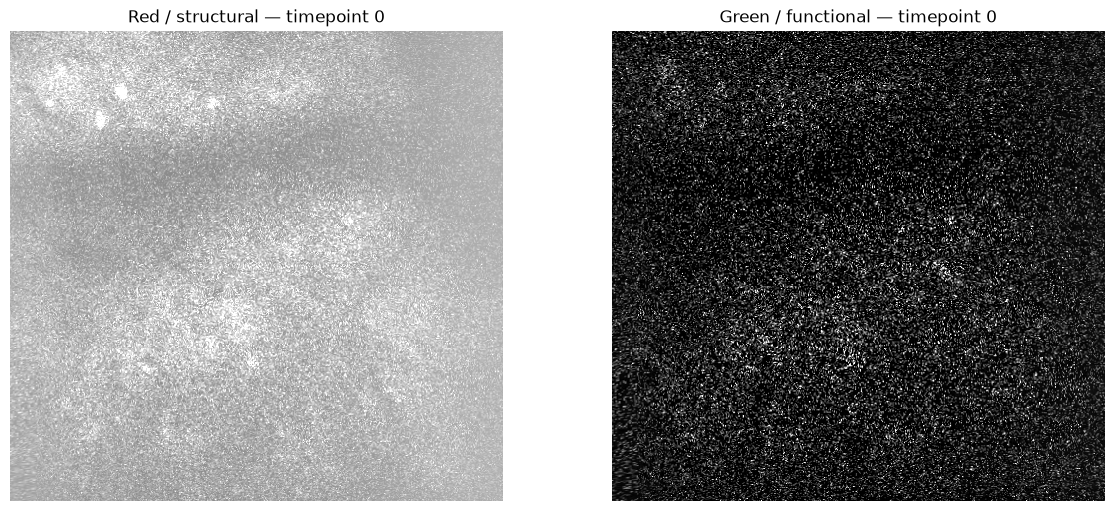

In [18]:
import matplotlib.pyplot as plt

PREVIEW_TIMEPOINT = 0


def scale_to_uint8(frame, limits, gamma=1.0):
    low, high = limits
    frame = np.asarray(frame, dtype=np.float32)
    scaled = np.clip((frame - low) / (high - low), 0, 1)
    # Conventional display gamma: values above 1 brighten midtones.
    scaled = scaled ** (1.0 / float(gamma))
    return np.round(255 * scaled).astype(np.uint8)


def grayscale_to_rgb(gray):
    # MP4 expects three colour planes; repeating gray preserves black and white.
    return np.repeat(gray[..., None], 3, axis=2)


with source_context() as source_handle:
    red_raw = read_source_frame(PREVIEW_TIMEPOINT, 'red', source_handle)
    green_raw = read_source_frame(PREVIEW_TIMEPOINT, 'green', source_handle)

red_preview = grayscale_to_rgb(
    scale_to_uint8(red_raw, red_limits, GAMMA))
green_preview = grayscale_to_rgb(
    scale_to_uint8(green_raw, green_limits, GAMMA))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].imshow(red_preview, interpolation='nearest')
axes[0].set_title(f'Red / structural — timepoint {PREVIEW_TIMEPOINT}')
axes[1].imshow(green_preview, interpolation='nearest')
axes[1].set_title(f'Green / functional — timepoint {PREVIEW_TIMEPOINT}')
for ax in axes:
    ax.axis('off')
plt.show()


## Export the complete videos

Frames are streamed from the selected source one timepoint at a time. Existing videos are protected unless `OVERWRITE=True`. Both channels are grayscale; the side-by-side video places structural/red on the left and functional/green on the right.


In [19]:
def make_writer(path, width, height):
    if path.exists() and not OVERWRITE:
        raise FileExistsError(f'{path} exists; set OVERWRITE=True to replace it')
    writer = imageio_ffmpeg.write_frames(
        str(path), (int(width), int(height)), fps=float(FPS),
        codec='libx264', pix_fmt_in='rgb24', pix_fmt_out='yuv420p',
        output_params=[
            '-crf', str(VIDEO_CRF), '-preset', VIDEO_PRESET,
            '-tag:v', 'avc1', '-profile:v', 'main', '-level:v', '4.1',
            '-movflags', '+faststart',
        ],
        macro_block_size=1,
    )
    writer.send(None)
    return writer


writers = {}
try:
    if WRITE_RED_VIDEO:
        writers['red'] = make_writer(RED_VIDEO, video_width, video_height)
    if WRITE_GREEN_VIDEO:
        writers['green'] = make_writer(GREEN_VIDEO, video_width, video_height)
    if WRITE_SIDE_BY_SIDE_VIDEO:
        writers['side_by_side'] = make_writer(
            SIDE_BY_SIDE_VIDEO, 2 * video_width, video_height)

    with source_context() as source_handle:
        for timepoint in range(n_timepoints):
            red_raw = read_source_frame(
                timepoint, 'red', source_handle
            )[:video_height, :video_width]
            green_raw = read_source_frame(
                timepoint, 'green', source_handle
            )[:video_height, :video_width]
            red_rgb = grayscale_to_rgb(
                scale_to_uint8(red_raw, red_limits, GAMMA))
            green_rgb = grayscale_to_rgb(
                scale_to_uint8(green_raw, green_limits, GAMMA))

            if 'red' in writers:
                writers['red'].send(red_rgb.tobytes())
            if 'green' in writers:
                writers['green'].send(green_rgb.tobytes())
            if 'side_by_side' in writers:
                combined = np.concatenate([red_rgb, green_rgb], axis=1)
                writers['side_by_side'].send(combined.tobytes())
            if (timepoint + 1) % 500 == 0 or timepoint + 1 == n_timepoints:
                print(f'Encoded {timepoint + 1:>7}/{n_timepoints} timepoints')
finally:
    for writer in writers.values():
        writer.close()

video_metadata = {
    'video_source': VIDEO_SOURCE,
    'source': SOURCE_DESCRIPTION,
    'n_timepoints': int(n_timepoints),
    'fps': float(FPS),
    'duration_seconds': float(n_timepoints / FPS),
    'source_shape_yx': [int(original_height), int(original_width)],
    'video_shape_yx': [int(video_height), int(video_width)],
    'red_channel_zero_based': int(STRUCTURAL_CHANNEL_ZERO_BASED),
    'green_channel_zero_based': int(FUNCTIONAL_CHANNEL_ZERO_BASED),
    'contrast_sample_frames': int(len(sample_timepoints)),
    'black_percentile': float(BLACK_PERCENTILE),
    'white_percentile': float(WHITE_PERCENTILE),
    'gamma': float(GAMMA),
    'red_limits': list(red_limits), 'green_limits': list(green_limits),
    'display_mode': 'grayscale_rgb',
    'codec': 'libx264', 'crf': int(VIDEO_CRF), 'preset': VIDEO_PRESET,
    'outputs': {key: str(path) for key, path in {
        'red': RED_VIDEO if WRITE_RED_VIDEO else None,
        'green': GREEN_VIDEO if WRITE_GREEN_VIDEO else None,
        'side_by_side': SIDE_BY_SIDE_VIDEO if WRITE_SIDE_BY_SIDE_VIDEO else None,
    }.items() if path is not None},
}
metadata_path = OUTPUT_DIR / f'{VIDEO_STEM}_video_metadata.json'
metadata_path.write_text(json.dumps(video_metadata, indent=2))
print('Saved metadata:', metadata_path)
for name, path in video_metadata['outputs'].items():
    print(f'Saved {name}: {path}')


Encoded     500/10604 timepoints
Encoded    1000/10604 timepoints
Encoded    1500/10604 timepoints
Encoded    2000/10604 timepoints
Encoded    2500/10604 timepoints
Encoded    3000/10604 timepoints
Encoded    3500/10604 timepoints
Encoded    4000/10604 timepoints
Encoded    4500/10604 timepoints
Encoded    5000/10604 timepoints
Encoded    5500/10604 timepoints
Encoded    6000/10604 timepoints
Encoded    6500/10604 timepoints
Encoded    7000/10604 timepoints
Encoded    7500/10604 timepoints
Encoded    8000/10604 timepoints
Encoded    8500/10604 timepoints
Encoded    9000/10604 timepoints
Encoded    9500/10604 timepoints
Encoded   10000/10604 timepoints
Encoded   10500/10604 timepoints
Encoded   10604/10604 timepoints
Saved metadata: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-217_date-20260731/funcimg/run-02/videos/71rtask_00009_dynamic_bidiphase_destriped_undistorted_raw_video_metadata.json
Saved red: /Volumes/behrens/meg/3x3_field_magnit

## Validate the finished MP4 files

Run this after the export cell completes. FFmpeg decodes each complete video without displaying it. A return code of zero confirms that the MP4 index was finalized and its video stream is readable. Interrupted notebook cells commonly leave an MP4 that exists on disk but cannot be opened by QuickTime.


In [20]:
ffmpeg_executable = imageio_ffmpeg.get_ffmpeg_exe()
finished_videos = [
    path for enabled, path in [
        (WRITE_RED_VIDEO, RED_VIDEO),
        (WRITE_GREEN_VIDEO, GREEN_VIDEO),
        (WRITE_SIDE_BY_SIDE_VIDEO, SIDE_BY_SIDE_VIDEO),
    ] if enabled
]

all_videos_valid = True
for video_path in finished_videos:
    if not video_path.is_file():
        print('MISSING:', video_path)
        all_videos_valid = False
        continue
    result = subprocess.run(
        [ffmpeg_executable, '-v', 'error', '-i', str(video_path),
         '-map', '0:v:0', '-f', 'null', '-'],
        capture_output=True, text=True)
    size_mb = video_path.stat().st_size / 1e6
    if result.returncode == 0:
        print(f'VALID ({size_mb:.1f} MB): {video_path}')
    else:
        all_videos_valid = False
        print(f'INVALID ({size_mb:.1f} MB): {video_path}')
        print(result.stderr.strip())

if all_videos_valid:
    print('All requested MP4 files decoded successfully.')
else:
    print('At least one MP4 is incomplete or corrupt. Set OVERWRITE=True and rerun the export cell without interrupting it.')


VALID (918.3 MB): /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-217_date-20260731/funcimg/run-02/videos/71rtask_00009_dynamic_bidiphase_destriped_undistorted_raw_red_structural.mp4
VALID (1249.1 MB): /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-217_date-20260731/funcimg/run-02/videos/71rtask_00009_dynamic_bidiphase_destriped_undistorted_raw_green_functional.mp4
VALID (2152.7 MB): /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-217_date-20260731/funcimg/run-02/videos/71rtask_00009_dynamic_bidiphase_destriped_undistorted_raw_red_green_side_by_side.mp4
All requested MP4 files decoded successfully.
